In [37]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [38]:

# Set the dataset path
DATA_PATH = "./data"

# Convert images into tensors
transform = transforms.ToTensor()

# Download the training dataset
train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=transform
)

# Download the testing dataset
test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))


Training images: 50000
Testing images: 10000


In [39]:

from torch.utils.data import DataLoader

# Create training and testing DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))


Training batches: 782
Testing batches: 157


In [40]:

# Get one batch of images and labels
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Single image shape:", images[0].shape)


Images shape: torch.Size([64, 3, 32, 32])
Labels shape: torch.Size([64])
Single image shape: torch.Size([3, 32, 32])


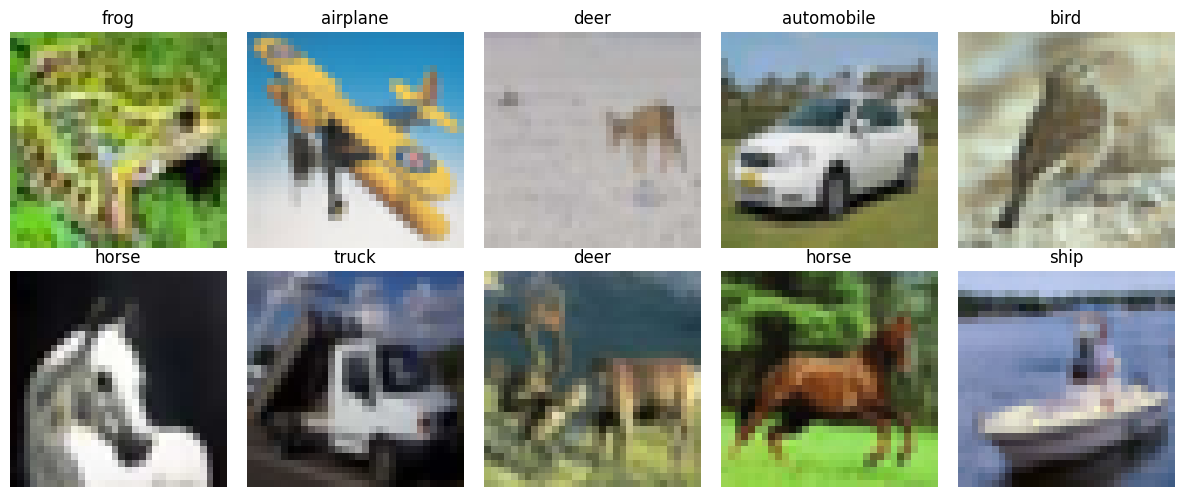

In [41]:

# CIFAR-10 class names
classes = train_dataset.classes

# Display 10 sample images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0)
    ax.imshow(image)
    ax.set_title(classes[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [42]:
import torch
import torch.nn as nn
import torch.optim as optim


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


# CNN baseline model
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Input: 3 x 32 x 32
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 32 x 16 x 16

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)   # 64 x 8 x 8
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)  # CIFAR-10 has 10 classes
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = BaselineCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

Using device: cuda
BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [43]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    total_images = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_images += images.size(0)

    return total_loss / total_images


def evaluate_model(model, test_loader, criterion, device):
    model.eval()
    total_loss = 0
    total_images = 0
    correct = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            total_images += images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()

    test_loss = total_loss / total_images
    accuracy = 100 * correct / total_images
    return test_loss, accuracy

In [44]:
epochs = 5

history = {
    "train_loss": [],
    "test_loss": [],
    "test_accuracy": []
}

for epoch in range(epochs):
    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    test_loss, test_accuracy = evaluate_model(
        model, test_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)
    history["test_accuracy"].append(test_accuracy)

    print(
        f"Epoch [{epoch + 1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

Epoch [1/5] | Train Loss: 1.4846 | Test Loss: 1.1947 | Test Accuracy: 57.84%
Epoch [2/5] | Train Loss: 1.0977 | Test Loss: 1.0212 | Test Accuracy: 64.43%
Epoch [3/5] | Train Loss: 0.9428 | Test Loss: 0.9606 | Test Accuracy: 66.40%
Epoch [4/5] | Train Loss: 0.8513 | Test Loss: 0.9090 | Test Accuracy: 68.70%
Epoch [5/5] | Train Loss: 0.7679 | Test Loss: 0.8717 | Test Accuracy: 70.12%


In [45]:
import pandas as pd

results_table = pd.DataFrame({
  "Epoch": range(1, len(history["train_loss"]) + 1),
    "Training Loss": history["train_loss"],
    "Test Loss": history["test_loss"],
    "Test Accuracy": history["test_accuracy"]
})

display(results_table.style
    .hide(axis="index")
    .format({
        "Training Loss": "{:.4f}",
        "Test Loss": "{:.4f}",
        "Test Accuracy": "{:.2f}%"
    }))

Epoch,Training Loss,Test Loss,Test Accuracy
1,1.4846,1.1947,57.84%
2,1.0977,1.0212,64.43%
3,0.9428,0.9606,66.40%
4,0.8513,0.9090,68.70%
5,0.7679,0.8717,70.12%


## Data augmentation

In [46]:
import random
import numpy as np
from torch.utils.data import DataLoader

AUG_BATCH_SIZE = 64
AUG_EPOCHS = 5
AUG_SEED = 42

CIFAR_MEAN = [0.4914, 0.4822, 0.4465]
CIFAR_STD = [0.2023, 0.1994, 0.2010]

class GaussianNoise:
    def __init__(self, std=0.03):
        self.std = std

    def __call__(self, tensor):
        return (tensor + torch.randn_like(tensor) * self.std).clamp(0, 1)

augmentation_configs = {
    "Baseline (No Augmentation)": [],
    "Horizontal Flip": ["flip"],
    "Resized Crop + Flip": ["crop", "flip"],
    "Flip + Rotation": ["flip", "rotation"],
    "Color Jitter + Noise": ["color", "noise"],
    "All Augmentations": ["crop", "flip", "rotation", "color", "noise"],
}

def make_train_transform(selected):
    steps = []

    if "crop" in selected:
        steps.append(
            transforms.RandomResizedCrop(
                32, scale=(0.85, 1.0), ratio=(0.9, 1.1)
            )
        )
    if "flip" in selected:
        steps.append(transforms.RandomHorizontalFlip(p=0.5))
    if "rotation" in selected:
        steps.append(transforms.RandomRotation(10))
    if "color" in selected:
        steps.append(
            transforms.ColorJitter(0.2, 0.2, 0.2, 0.03)
        )

    steps.append(transforms.ToTensor())

    if "noise" in selected:
        steps.append(GaussianNoise(0.03))

    steps.append(transforms.Normalize(CIFAR_MEAN, CIFAR_STD))
    return transforms.Compose(steps)

test_transform_aug = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

print("Ready:", len(augmentation_configs), "augmentation settings")

Ready: 6 augmentation settings


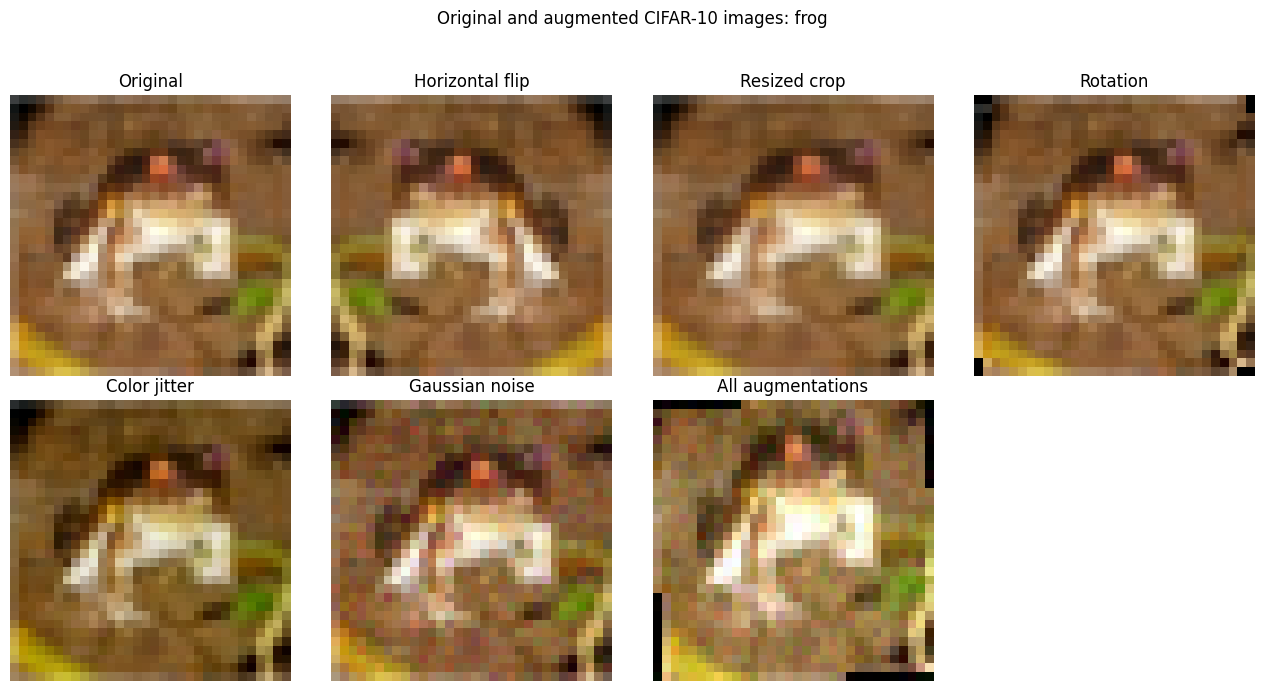

In [47]:
import torch
import matplotlib.pyplot as plt

class GaussianNoise:
    def __init__(self, std=0.03):
        self.std = std

    def __call__(self, tensor):
        return (tensor + torch.randn_like(tensor) * self.std).clamp(0, 1)

CIFAR_MEAN = [0.4914, 0.4822, 0.4465]
CIFAR_STD = [0.2023, 0.1994, 0.2010]

original_tensor, label = train_dataset[0]
original_pil = transforms.ToPILImage()(original_tensor)

preview_transforms = {
    "Original": transforms.ToTensor(),

    "Horizontal flip": transforms.Compose([
        transforms.RandomHorizontalFlip(p=1.0),
        transforms.ToTensor()
    ]),

    "Resized crop": transforms.Compose([
        transforms.RandomResizedCrop(
            32, scale=(0.85, 1.0), ratio=(0.9, 1.1)
        ),
        transforms.ToTensor()
    ]),

    "Rotation": transforms.Compose([
        transforms.RandomRotation(10),
        transforms.ToTensor()
    ]),

    "Color jitter": transforms.Compose([
        transforms.ColorJitter(0.2, 0.2, 0.2, 0.03),
        transforms.ToTensor()
    ]),

    "Gaussian noise": transforms.Compose([
        transforms.ToTensor(),
        GaussianNoise(0.03)
    ]),

    "All augmentations": transforms.Compose([
        transforms.RandomResizedCrop(32, scale=(0.85, 1.0)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(10),
        transforms.ColorJitter(0.2, 0.2, 0.2, 0.03),
        transforms.ToTensor(),
        GaussianNoise(0.03),
        transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
    ]),
}

torch.manual_seed(AUG_SEED)
fig, axes = plt.subplots(2, 4, figsize=(13, 7))

for ax, (name, transform_fn) in zip(axes.flat, preview_transforms.items()):
    image = transform_fn(original_pil)

    if name == "All augmentations":
        mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
        std = torch.tensor(CIFAR_STD).view(3, 1, 1)
        image = image * std + mean

    ax.imshow(image.clamp(0, 1).permute(1, 2, 0))
    ax.set_title(name)
    ax.axis("off")

axes.flat[-1].axis("off")
fig.suptitle(f"Original and augmented CIFAR-10 images: {classes[label]}")
fig.tight_layout(rect=(0, 0, 1, 0.94), h_pad=2)
plt.savefig("augmentation_examples.png", dpi=200, bbox_inches="tight")
plt.show()

In [48]:
test_dataset_aug = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=False,
    transform=test_transform_aug
)

test_loader_aug = DataLoader(
    test_dataset_aug,
    batch_size=AUG_BATCH_SIZE,
    shuffle=False
)

augmentation_histories = {}

for config_name, selected in augmentation_configs.items():
    random.seed(AUG_SEED)
    np.random.seed(AUG_SEED)
    torch.manual_seed(AUG_SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(AUG_SEED)

    train_dataset_aug = torchvision.datasets.CIFAR10(
        root=DATA_PATH,
        train=True,
        download=False,
        transform=make_train_transform(selected)
    )

    train_loader_aug = DataLoader(
        train_dataset_aug,
        batch_size=AUG_BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(AUG_SEED)
    )

    experiment_model = BaselineCNN().to(device)
    experiment_criterion = nn.CrossEntropyLoss()
    experiment_optimizer = optim.Adam(
        experiment_model.parameters(), lr=0.001
    )

    experiment_history = {
        "train_loss": [],
        "test_loss": [],
        "test_accuracy": []
    }

    print(f"\n=== {config_name} ===")

    for epoch in range(AUG_EPOCHS):
        train_loss = train_one_epoch(
            experiment_model,
            train_loader_aug,
            experiment_criterion,
            experiment_optimizer,
            device
        )

        test_loss, test_accuracy = evaluate_model(
            experiment_model,
            test_loader_aug,
            experiment_criterion,
            device
        )

        experiment_history["train_loss"].append(train_loss)
        experiment_history["test_loss"].append(test_loss)
        experiment_history["test_accuracy"].append(test_accuracy)

        print(
            f"Epoch {epoch + 1}/{AUG_EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Test loss: {test_loss:.4f} | "
            f"Test accuracy: {test_accuracy:.2f}%"
        )

    augmentation_histories[config_name] = experiment_history

print("\nAll augmentation experiments completed.")


=== Baseline (No Augmentation) ===
Epoch 1/5 | Train loss: 1.2980 | Test loss: 1.0446 | Test accuracy: 62.57%
Epoch 2/5 | Train loss: 0.9206 | Test loss: 0.9021 | Test accuracy: 68.28%
Epoch 3/5 | Train loss: 0.7583 | Test loss: 0.8726 | Test accuracy: 69.27%
Epoch 4/5 | Train loss: 0.6371 | Test loss: 0.8758 | Test accuracy: 70.55%
Epoch 5/5 | Train loss: 0.5364 | Test loss: 0.8712 | Test accuracy: 71.67%

=== Horizontal Flip ===
Epoch 1/5 | Train loss: 1.2868 | Test loss: 1.0034 | Test accuracy: 64.80%
Epoch 2/5 | Train loss: 0.9314 | Test loss: 0.9000 | Test accuracy: 68.39%
Epoch 3/5 | Train loss: 0.8000 | Test loss: 0.8692 | Test accuracy: 69.99%
Epoch 4/5 | Train loss: 0.7102 | Test loss: 0.7985 | Test accuracy: 72.26%
Epoch 5/5 | Train loss: 0.6434 | Test loss: 0.7791 | Test accuracy: 73.69%

=== Resized Crop + Flip ===
Epoch 1/5 | Train loss: 1.3598 | Test loss: 1.0628 | Test accuracy: 62.66%
Epoch 2/5 | Train loss: 1.0253 | Test loss: 0.9575 | Test accuracy: 66.55%
Epoch 3/5 

In [49]:
rows = []

for config_name, h in augmentation_histories.items():
    rows.append({
        "Augmentation": config_name,
        "Train Loss": h["train_loss"][-1],
        "Test Loss": h["test_loss"][-1],
        "Test Accuracy (%)": h["test_accuracy"][-1],
    })

augmentation_results = pd.DataFrame(rows)
augmentation_results = augmentation_results.sort_values(
    by=["Test Accuracy (%)", "Test Loss"],
    ascending=[False, True]
).reset_index(drop=True)

display(augmentation_results.round(4))
augmentation_results.to_csv("augmentation_results.csv", index=False)

best = augmentation_results.iloc[0]
control = augmentation_results[
    augmentation_results["Augmentation"] == "Baseline (No Augmentation)"
].iloc[0]

print(f"Best setting: {best['Augmentation']}")
print(f"Best test accuracy: {best['Test Accuracy (%)']:.2f}%")
print(
    "Difference from no augmentation: "
    f"{best['Test Accuracy (%)'] - control['Test Accuracy (%)']:+.2f} percentage points"
)

,Augmentation,Train Loss,Test Loss,Test Accuracy (%)
0,Horizontal Flip,0.6434,0.7791,73.69
1,Resized Crop + Flip,0.7662,0.7878,73.48
2,Flip + Rotation,0.7662,0.7946,72.61
3,Baseline (No Augmentation),0.5364,0.8712,71.67
4,All Augmentations,0.9324,0.8569,70.69
5,Color Jitter + Noise,0.6343,0.8929,70.24


Best setting: Horizontal Flip
Best test accuracy: 73.69%
Difference from no augmentation: +2.02 percentage points


# CNN Architecture Experiments

In [50]:
##5.3
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Experiment settings
EPOCHS = 10
LEARNING_RATE = 0.001

Using device: cuda


In [51]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [52]:
class DeeperCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [53]:
class MoreFiltersCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [54]:
def run_experiment(model_class, model_name):

    model = model_class().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    history = {
        "train_loss": [],
        "test_loss": [],
        "test_accuracy": []
    }

    print("\nTraining:", model_name)

    for epoch in range(EPOCHS):

        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        test_loss, test_accuracy = evaluate_model(
            model,
            test_loader,
            criterion,
            device
        )

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["test_accuracy"].append(test_accuracy)

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Accuracy: {test_accuracy:.2f}%"
        )

    return model, history

In [55]:
results = {}

baseline_model, results["Baseline CNN"] = run_experiment(
    BaselineCNN,
    "Baseline CNN"
)

deeper_model, results["Deeper CNN"] = run_experiment(
    DeeperCNN,
    "Deeper CNN"
)

filters_model, results["More Filters CNN"] = run_experiment(
    MoreFiltersCNN,
    "More Filters CNN"
)


Training: Baseline CNN
Epoch [1/10] Train Loss: 1.5432 | Test Loss: 1.3083 | Test Accuracy: 52.83%
Epoch [2/10] Train Loss: 1.2082 | Test Loss: 1.1277 | Test Accuracy: 60.02%
Epoch [3/10] Train Loss: 1.0595 | Test Loss: 1.0419 | Test Accuracy: 63.36%
Epoch [4/10] Train Loss: 0.9574 | Test Loss: 0.9540 | Test Accuracy: 66.79%
Epoch [5/10] Train Loss: 0.8725 | Test Loss: 0.9425 | Test Accuracy: 67.29%
Epoch [6/10] Train Loss: 0.8045 | Test Loss: 0.9204 | Test Accuracy: 67.94%
Epoch [7/10] Train Loss: 0.7541 | Test Loss: 0.9434 | Test Accuracy: 67.49%
Epoch [8/10] Train Loss: 0.6988 | Test Loss: 0.8984 | Test Accuracy: 68.86%
Epoch [9/10] Train Loss: 0.6490 | Test Loss: 0.9151 | Test Accuracy: 69.65%
Epoch [10/10] Train Loss: 0.5964 | Test Loss: 0.8787 | Test Accuracy: 70.13%

Training: Deeper CNN
Epoch [1/10] Train Loss: 1.5225 | Test Loss: 1.2122 | Test Accuracy: 56.97%
Epoch [2/10] Train Loss: 1.0489 | Test Loss: 0.9578 | Test Accuracy: 66.05%
Epoch [3/10] Train Loss: 0.8679 | Test Lo

In [56]:
import pandas as pd

comparison = []

for name, history in results.items():

    comparison.append({
        "Architecture": name,
        "Training Loss": history["train_loss"][-1],
        "Test Loss": history["test_loss"][-1],
        "Test Accuracy": history["test_accuracy"][-1]
    })

results_df = pd.DataFrame(comparison)

print(results_df.to_string(index=False))

    Architecture  Training Loss  Test Loss  Test Accuracy
    Baseline CNN       0.596421   0.878734          70.13
      Deeper CNN       0.301315   0.980749          72.30
More Filters CNN       0.367492   1.030403          70.05


In [57]:
best_model_name = results_df.loc[
    results_df["Test Accuracy"].idxmax(),
    "Architecture"
]

print("Best Architecture:", best_model_name)

Best Architecture: Deeper CNN


## Final Model Training

In [59]:
# Code 1: Final Model Configuration

import os
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

FINAL_SEED = 42
FINAL_EPOCHS = 10
FINAL_BATCH_SIZE = 64
FINAL_LR = 0.001

random.seed(FINAL_SEED)
np.random.seed(FINAL_SEED)
torch.manual_seed(FINAL_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(FINAL_SEED)

# Training dataset with Horizontal Flip
final_train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=make_train_transform(["flip"])
)

# Testing dataset
final_test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=test_transform_aug
)

# DataLoaders
final_train_loader = DataLoader(
    final_train_dataset,
    batch_size=FINAL_BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(FINAL_SEED)
)

final_test_loader = DataLoader(
    final_test_dataset,
    batch_size=FINAL_BATCH_SIZE,
    shuffle=False
)

# Final CNN Model
final_model = DeeperCNN().to(device)

final_criterion = nn.CrossEntropyLoss()

final_optimizer = optim.Adam(
    final_model.parameters(),
    lr=FINAL_LR
)

final_history = {
    "train_loss": [],
    "test_loss": [],
    "test_accuracy": []
}

print("Final Model: DeeperCNN + Horizontal Flip")
print("Optimizer: Adam")
print("Learning Rate:", FINAL_LR)
print("Batch Size:", FINAL_BATCH_SIZE)
print("Epochs:", FINAL_EPOCHS)
print("Device:", device)

Final Model: DeeperCNN + Horizontal Flip
Optimizer: Adam
Learning Rate: 0.001
Batch Size: 64
Epochs: 10
Device: cuda


In [60]:
# Code 2: Final Model Training and Testing

for epoch in range(FINAL_EPOCHS):

    train_loss = train_one_epoch(
        final_model,
        final_train_loader,
        final_criterion,
        final_optimizer,
        device
    )

    test_loss, test_accuracy = evaluate_model(
        final_model,
        final_test_loader,
        final_criterion,
        device
    )

    final_history["train_loss"].append(float(train_loss))
    final_history["test_loss"].append(float(test_loss))
    final_history["test_accuracy"].append(float(test_accuracy))

    print(
        f"Epoch {epoch+1}/{FINAL_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

final_metrics = {
    "training_loss": final_history["train_loss"][-1],
    "test_loss": final_history["test_loss"][-1],
    "test_accuracy_percent": final_history["test_accuracy"][-1],
    "architecture": "DeeperCNN",
    "augmentation": "Horizontal Flip",
    "optimizer": "Adam",
    "learning_rate": FINAL_LR,
    "batch_size": FINAL_BATCH_SIZE,
    "epochs": FINAL_EPOCHS,
    "seed": FINAL_SEED
}

print("\nFINAL RESULTS:")
print(json.dumps(final_metrics, indent=2))

Epoch 1/10 | Train Loss: 1.3920 | Test Loss: 1.0802 | Test Accuracy: 61.44%
Epoch 2/10 | Train Loss: 0.9621 | Test Loss: 0.9063 | Test Accuracy: 68.69%
Epoch 3/10 | Train Loss: 0.7807 | Test Loss: 0.8038 | Test Accuracy: 72.42%
Epoch 4/10 | Train Loss: 0.6744 | Test Loss: 0.7689 | Test Accuracy: 73.29%
Epoch 5/10 | Train Loss: 0.6028 | Test Loss: 0.7118 | Test Accuracy: 76.12%
Epoch 6/10 | Train Loss: 0.5410 | Test Loss: 0.6769 | Test Accuracy: 77.40%
Epoch 7/10 | Train Loss: 0.4906 | Test Loss: 0.7296 | Test Accuracy: 75.73%
Epoch 8/10 | Train Loss: 0.4475 | Test Loss: 0.7002 | Test Accuracy: 77.61%
Epoch 9/10 | Train Loss: 0.4134 | Test Loss: 0.7146 | Test Accuracy: 76.94%
Epoch 10/10 | Train Loss: 0.3755 | Test Loss: 0.7437 | Test Accuracy: 77.39%

FINAL RESULTS:
{
  "training_loss": 0.3755073469352722,
  "test_loss": 0.7437499475479126,
  "test_accuracy_percent": 77.39,
  "architecture": "DeeperCNN",
  "augmentation": "Horizontal Flip",
  "optimizer": "Adam",
  "learning_rate": 0.0

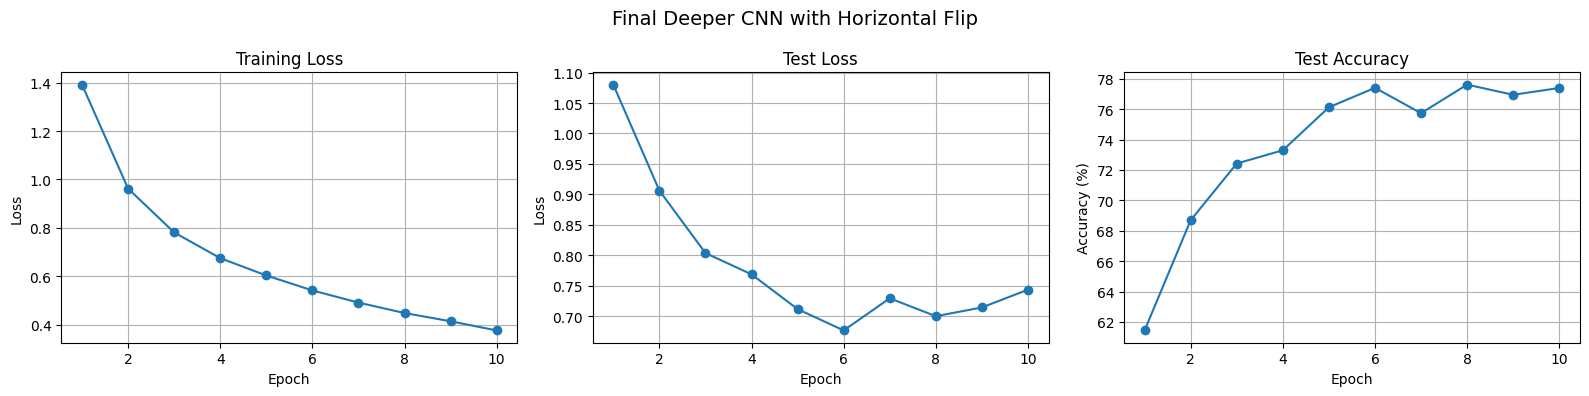

In [62]:
# Code 3: Final Model Performance Graphs

import matplotlib.pyplot as plt

epochs = range(1, len(final_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Training Loss
axes[0].plot(
    epochs,
    final_history["train_loss"],
    marker="o"
)
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True)

# 2. Test Loss
axes[1].plot(
    epochs,
    final_history["test_loss"],
    marker="o"
)
axes[1].set_title("Test Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(True)

# 3. Test Accuracy
axes[2].plot(
    epochs,
    final_history["test_accuracy"],
    marker="o"
)
axes[2].set_title("Test Accuracy")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Accuracy (%)")
axes[2].grid(True)

plt.suptitle(
    "Final Deeper CNN with Horizontal Flip",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "final_model_graphs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

In [63]:
# Code 4: Final Model vs Baseline Comparison

report_baseline = {
    "training_loss": 0.7547,
    "test_loss": 0.8623,
    "test_accuracy_percent": 69.88
}

comparison_df = pd.DataFrame([
    {
        "Model": "Baseline CNN (5 epochs)",
        "Training Loss": report_baseline["training_loss"],
        "Test Loss": report_baseline["test_loss"],
        "Test Accuracy (%)": report_baseline["test_accuracy_percent"]
    },
    {
        "Model": "Final Deeper CNN + Flip (10 epochs)",
        "Training Loss": final_metrics["training_loss"],
        "Test Loss": final_metrics["test_loss"],
        "Test Accuracy (%)": final_metrics["test_accuracy_percent"]
    }
])

print(comparison_df.to_string(index=False))

accuracy_difference = (
    final_metrics["test_accuracy_percent"] - 69.88
)

print(
    f"Accuracy Difference: "
    f"{accuracy_difference:+.2f} percentage points"
)

                              Model  Training Loss  Test Loss  Test Accuracy (%)
            Baseline CNN (5 epochs)       0.754700    0.86230              69.88
Final Deeper CNN + Flip (10 epochs)       0.375507    0.74375              77.39
Accuracy Difference: +7.51 percentage points


In [64]:
# Code 5: Save Final Model and Results

# Save comparison results
comparison_df.to_csv(
    "final_vs_baseline.csv",
    index=False
)

# Save training history
pd.DataFrame({
    "Epoch": epoch_axis,
    **final_history
}).to_csv(
    "final_training_history.csv",
    index=False
)

# Save final metrics
with open("final_metrics.json", "w") as f:
    json.dump(final_metrics, f, indent=2)

# Save trained CNN model
torch.save(
    {
        "model_state_dict": final_model.state_dict(),
        "model_class": "DeeperCNN",
        "metrics": final_metrics,
        "history": final_history
    },
    "final_cnn_checkpoint.pth"
)

print("Final model and results saved successfully!")

Final model and results saved successfully!
